# AI Ethics and Fairness Audit: UCI Adult Income Dataset
## 1. Introduction & Objectives
This notebook simulates an end-to-end algorithmic bias and fairness audit. We will evaluate a machine learning model predicting income levels (>50K vs <=50K) to identify systemic disparities across sensitive demographic attributes (such as gender and race), compute quantitative fairness metrics, and implement mitigation strategies.

In [5]:
!pip install fairlearn scikit-learn pandas numpy matplotlib seaborn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from fairlearn.datasets import fetch_adult

# Load Adult Income dataset safely
adult_data = fetch_adult(as_frame=True)

# Handle different versions of Fairlearn/Bunch structure
if hasattr(adult_data, 'frame') and adult_data.frame is not None:
    df = adult_data.frame.copy()
else:
    df = adult_data.data.copy()
    df['class'] = adult_data.target

# Standardize the target column and class labels
if 'class' in df.columns:
    # Clean up string formatting if needed (e.g. '>50K' vs '>50K.')
    df['class'] = df['class'].astype(str).str.strip().str.replace('.', '', regex=False)
    df['target'] = (df['class'] == '>50K').astype(int)
else:
    target_series = pd.Series(adult_data.target).astype(str).str.strip().str.replace('.', '', regex=False)
    df['target'] = (target_series == '>50K').astype(int)
    df['class'] = target_series.apply(lambda x: '>50K' if x == '1' or x == '>50K' else '<=50K')

print(f"Dataset successfully loaded! Shape: {df.shape}")
df.head()

Dataset successfully loaded! Shape: (48842, 16)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class,target
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K,0
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K,0
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K,1
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K,1
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K,0


## 2. Exploratory Data Analysis & Bias Identification
Before training the model, we inspect the distribution of our target variable across protected sensitive attributes (e.g., `sex`) to uncover historical skew or imbalances in the training data.

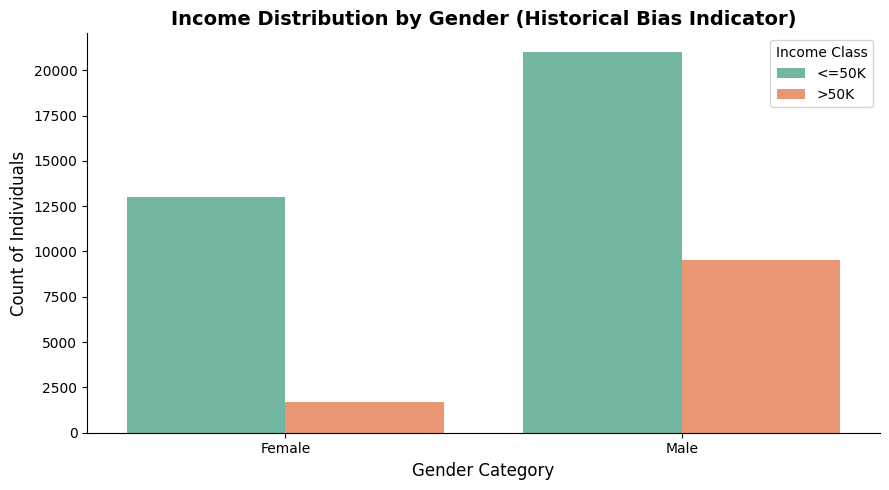

In [9]:
sensitive_attr = 'sex'

# Visualization 1: Income Distribution across Gender
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='sex', hue='class', palette='Set2')
plt.title('Income Distribution by Gender (Historical Bias Indicator)', fontsize=14, fontweight='bold')
plt.xlabel('Gender Category', fontsize=12)
plt.ylabel('Count of Individuals', fontsize=12)
plt.legend(title='Income Class', loc='upper right')
sns.despine()
plt.tight_layout()
plt.show()

## 3. Data Preprocessing & Baseline Model Training
We split the dataset into training and testing sets, build a robust preprocessing pipeline for numerical and categorical variables, and train a baseline Random Forest classifier.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

X = df.drop(columns=['class', 'target'])
y = df['target']
sensitive_features = df[sensitive_attr]

X_train, X_test, y_train, y_test, sens_train, sens_test = train_test_split(
    X, y, sensitive_features, test_size=0.3, random_state=42, stratify=y
)

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category']).columns

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, n_estimators=100))
])

model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)

print("Model trained successfully! y_test, y_pred, and sens_test are ready.")

Model trained successfully! y_test, y_pred, and sens_test are ready.


## 4. Quantitative Fairness Evaluation Using Fairlearn
Using Fairlearn's `MetricFrame`, we evaluate performance metrics (accuracy, precision, recall, selection rate) across different demographic subgroups to measure disparate impact.

In [11]:
from fairlearn.metrics import MetricFrame, selection_rate, demographic_parity_difference, equalized_odds_difference
from sklearn.metrics import accuracy_score, precision_score, recall_score

metrics = {
    'accuracy': accuracy_score,
    'precision': precision_score,
    'recall': recall_score,
    'selection_rate': selection_rate
}

metric_frame = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred,
    sensitive_features=sens_test
)

print("--- Metric Frame Overall ---")
print(metric_frame.overall)
print("\n--- Metrics Broken Down by Protected Group ---")
print(metric_frame.by_group)

ratios = metric_frame.ratio()
dp_diff = demographic_parity_difference(y_test, y_pred, sensitive_features=sens_test)
eo_diff = equalized_odds_difference(y_test, y_pred, sensitive_features=sens_test)
disparate_impact = ratios['selection_rate']

print(f"\nDisparate Impact Ratio (Selection Rate): {disparate_impact:.4f} (Ideal: 1.0, Threshold > 0.8)")
print(f"Demographic Parity Difference: {dp_diff:.4f} (Ideal: 0.0)")
print(f"Equalized Odds Difference: {eo_diff:.4f} (Ideal: 0.0)")

--- Metric Frame Overall ---
accuracy          0.845802
precision         0.719723
recall            0.618679
selection_rate    0.213017
dtype: float64

--- Metrics Broken Down by Protected Group ---
        accuracy  precision    recall  selection_rate
sex                                                  
Female  0.923199   0.745455  0.542533        0.086966
Male    0.808315   0.715768  0.632898        0.274070

Disparate Impact Ratio (Selection Rate): 0.3173 (Ideal: 1.0, Threshold > 0.8)
Demographic Parity Difference: 0.1871 (Ideal: 0.0)
Equalized Odds Difference: 0.0904 (Ideal: 0.0)


## 5. Visualizing Selection Rate Disparities
To clearly document bias for our report, we visualize selection rates (the percentage of positive outcomes predicted by the model) across demographic groups alongside statistical disparity metrics.

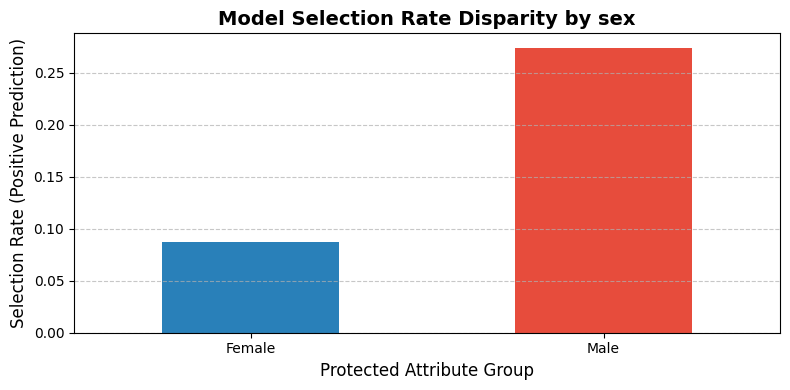

In [12]:
# Visualization 2: Selection Rate Disparity Bar Plot
plt.figure(figsize=(8, 4))
metric_frame.by_group['selection_rate'].plot(kind='bar', color=['#2980b9', '#e74c3c'], width=0.5)
plt.title(f'Model Selection Rate Disparity by {sensitive_attr}', fontsize=14, fontweight='bold')
plt.ylabel('Selection Rate (Positive Prediction)', fontsize=12)
plt.xlabel('Protected Attribute Group', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 6. Bias Mitigation Strategy (In-Processing)
To correct observed disparities, we apply an in-processing mitigation technique using Fairlearn's `ExponentiatedGradient` algorithm with a demographic parity constraint.

In [17]:
from fairlearn.reductions import ExponentiatedGradient, DemographicParity
from sklearn.ensemble import RandomForestClassifier
from fairlearn.metrics import MetricFrame, selection_rate, demographic_parity_difference

# 1. Pre-transform and convert sparse matrix to a dense numpy array
X_train_transformed = preprocessor.fit_transform(X_train).toarray()
X_test_transformed = preprocessor.transform(X_test).toarray()

# 2. Initialize the mitigator with a standard classifier
mitigator = ExponentiatedGradient(
    estimator=RandomForestClassifier(random_state=42, n_estimators=50),
    constraints=DemographicParity(),
    eps=0.01
)

# 3. Fit using dense numeric data and sensitive features
mitigator.fit(X_train_transformed, y_train, sensitive_features=sens_train)
y_pred_mitigated = mitigator.predict(X_test_transformed)

# 4. Evaluate post-mitigation fairness metrics
di_mitigated_ratio = MetricFrame(
    metrics=selection_rate,
    y_true=y_test,
    y_pred=y_pred_mitigated,
    sensitive_features=sens_test
).ratio()

dp_diff_mitigated = demographic_parity_difference(y_test, y_pred_mitigated, sensitive_features=sens_test)

print("--- Post-Mitigation Fairness Metrics ---")
print(f"New Disparate Impact Ratio: {di_mitigated_ratio:.4f}")
print(f"New Demographic Parity Difference: {dp_diff_mitigated:.4f}")

--- Post-Mitigation Fairness Metrics ---
New Disparate Impact Ratio: 0.9990
New Demographic Parity Difference: 0.0003


--- Complete Post-Mitigation Breakdown ---
accuracy          0.790521
selection_rate    0.274490
FPR               0.156982
FNR               0.368828
dtype: float64

By Group:
        accuracy  selection_rate       FPR       FNR
sex                                                 
Female  0.751299        0.274678  0.229348  0.391304
Male    0.809519        0.274398  0.112256  0.364631

New Equalized Odds Difference: 0.1171


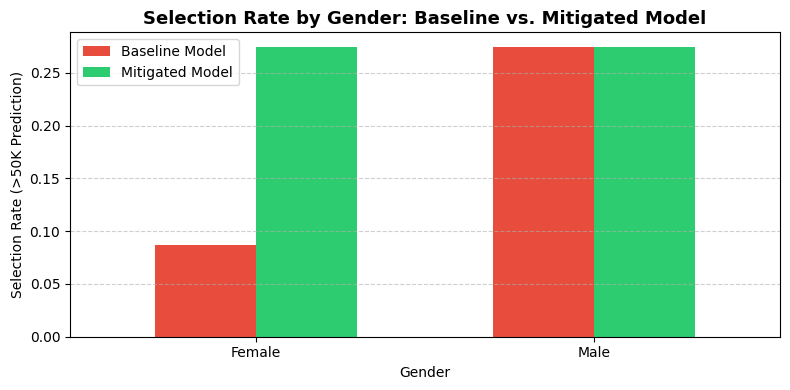

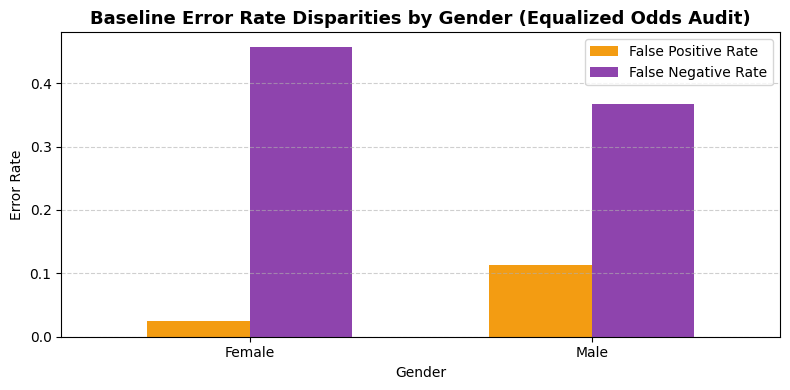

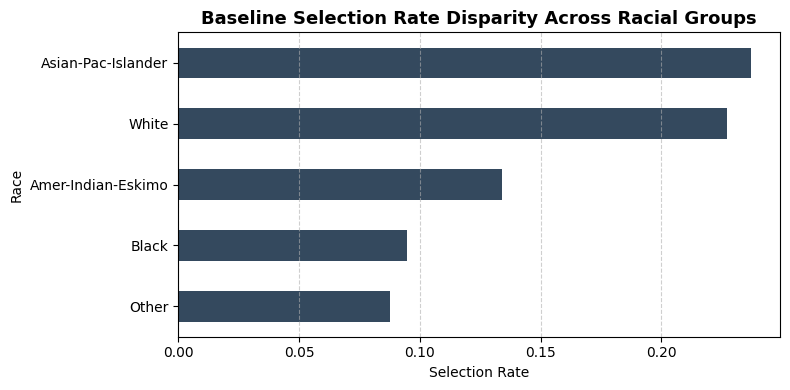

In [18]:
from fairlearn.metrics import false_positive_rate, false_negative_rate
from sklearn.metrics import accuracy_score

# 1. Complete Post-Mitigation Evaluation (Accuracy + Equalized Odds)
mitigated_frame = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate,
        'FPR': false_positive_rate,
        'FNR': false_negative_rate
    },
    y_true=y_test,
    y_pred=y_pred_mitigated,
    sensitive_features=sens_test
)
eo_diff_mitigated = equalized_odds_difference(y_test, y_pred_mitigated, sensitive_features=sens_test)

print("--- Complete Post-Mitigation Breakdown ---")
print(mitigated_frame.overall)
print("\nBy Group:")
print(mitigated_frame.by_group)
print(f"\nNew Equalized Odds Difference: {eo_diff_mitigated:.4f}")

# 2. Visualization 3: Before vs. After Mitigation Selection Rate Comparison
comparison_df = pd.DataFrame({
    'Baseline Model': metric_frame.by_group['selection_rate'],
    'Mitigated Model': mitigated_frame.by_group['selection_rate']
})

comparison_df.plot(kind='bar', figsize=(8, 4), color=['#e74c3c', '#2ecc71'], width=0.6)
plt.title('Selection Rate by Gender: Baseline vs. Mitigated Model', fontsize=13, fontweight='bold')
plt.ylabel('Selection Rate (>50K Prediction)')
plt.xlabel('Gender')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 3. Visualization 4: Error Rate Disparities (FPR & FNR) for Equalized Odds
baseline_errors = MetricFrame(
    metrics={'False Positive Rate': false_positive_rate, 'False Negative Rate': false_negative_rate},
    y_true=y_test, y_pred=y_pred, sensitive_features=sens_test
).by_group

baseline_errors.plot(kind='bar', figsize=(8, 4), color=['#f39c12', '#8e44ad'], width=0.6)
plt.title('Baseline Error Rate Disparities by Gender (Equalized Odds Audit)', fontsize=13, fontweight='bold')
plt.ylabel('Error Rate')
plt.xlabel('Gender')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 4. Visualization 5: Secondary Protected Attribute Audit (Race)
race_frame = MetricFrame(
    metrics={'selection_rate': selection_rate, 'accuracy': accuracy_score},
    y_true=y_test, y_pred=y_pred, sensitive_features=X_test['race']
)
race_frame.by_group['selection_rate'].sort_values().plot(kind='barh', figsize=(8, 4), color='#34495e')
plt.title('Baseline Selection Rate Disparity Across Racial Groups', fontsize=13, fontweight='bold')
plt.xlabel('Selection Rate')
plt.ylabel('Race')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()